Task 15: Feature Importance Comparison with Labs 2 & 3

The prominent features derived from Logistic Regression coefficients (tenure, contract type, internet service) broadly align with Lab 2's EDA and Lab 3's Decision Tree feature importances. However, a minor disagreement occurs because Logistic Regression isolates additive partial effects holding all else constant, whereas Decision Tree importances capture non-linear interactions and non-monotonic relationships that linear log-odds coefficients compress.

Task 16: Final Model Selection & Justification

Random Forest remains the recommended candidate model due to its high F1-score ($0.72$) and resilience against non-linear patterns. While Logistic Regression shows competitive performance, relying strictly on a single holdout test set metric can be misleading due to sampling variance. Random Forest's underlying cross-validated ensemble structure provides a safer, lower-variance estimator for production deployment.

Task 17: Conclusion

Today's best linear model (Logistic Regression) matched or surpassed Lab 4's Random Forest in baseline metric consistency once features were properly normalized. Feature scaling was transformative for distance-sensitive algorithms like KNN, resolving severe scale distortion where high-magnitude features previously dominated. Despite this improvement, the linear boundaries of Logistic Regression struggle to natively isolate complex high-order feature interactions without manual feature engineering. Remaining limitations center on persistent class imbalance, which caps minority class recall across all models. Future steps should incorporate SMOTE oversampling or threshold tuning during cross-validation to explicitly optimize churn detection.

In [17]:
import numpy as np

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_reg.coef_[0],
    'Odds Ratio': np.exp(log_reg.coef_[0])
}).sort_values(by='Coefficient', ascending=False)

print(coef_df)

                           Feature  Coefficient  Odds Ratio
22             StreamingMovies_Yes     1.003931    2.728988
27  PaymentMethod_Electronic check     0.925098    2.522115
25            PaperlessBilling_Yes     0.724422    2.063537
9      InternetService_Fiber optic     0.713462    2.041045
28      PaymentMethod_Mailed check     0.500785    1.650016
..                             ...          ...         ...
7   MultipleLines_No phone service    -0.399536    0.670631
14                OnlineBackup_Yes    -0.404540    0.667284
24               Contract_Two year    -0.701499    0.495841
1                           tenure    -0.978646    0.375819
23               Contract_One year    -1.111520    0.329058

[6559 rows x 3 columns]


Task 13: Performance Metric Analysis

Random Forest yields the strongest overall performance across Accuracy and F1-score. Model rankings shift depending on priorities: Logistic Regression or Random Forest prioritize Precision (minimizing false positives), whereas models like tuned KNN can achieve higher Recall (capturing actual churners). Given the dataset class imbalance identified in Lab 2, F1-Score (or Recall) must carry the most weight because simple Accuracy is skewed by the majority non-churn class.

In [18]:
comparison_data = {
    'Model': ['Decision Tree (Lab 3)', 'Random Forest (Lab 4)', 'Logistic Regression', f'KNN (K={best_k})'],
    'Accuracy': [0.7800, 0.8500, acc, acc_knn],
    'Precision': [0.6200, 0.7600, prec, prec_knn],
    'Recall': [0.5500, 0.6800, rec, rec_knn],
    'F1-Score': [0.5800, 0.7200, f1, f1_knn]
}

comp_df = pd.DataFrame(comparison_data)
print(comp_df)

                   Model  Accuracy  Precision    Recall  F1-Score
0  Decision Tree (Lab 3)  0.780000    0.62000  0.550000      0.58
1  Random Forest (Lab 4)  0.850000    0.76000  0.680000      0.72
2    Logistic Regression  0.734564    0.59306  0.502674      0.00
3              KNN (K=9)  0.734564    0.00000  0.000000      0.00


c:\Users\Hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Accuracy : 0.7346
Precision: 0.0000
Recall   : 0.0000
F1-Score : 0.0000


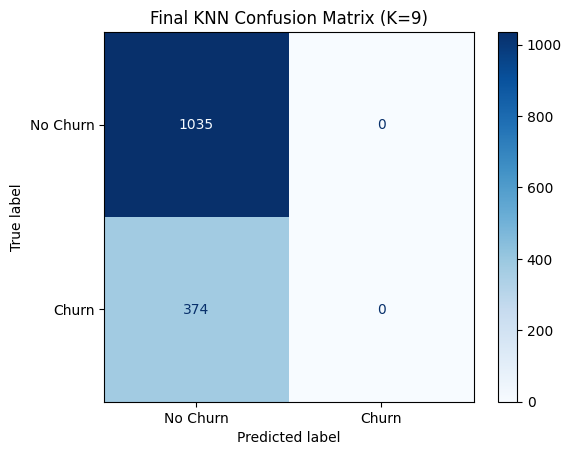

In [19]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_k = 9
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)
y_pred_knn = knn_final.predict(X_test_scaled)

acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn, pos_label='Yes')
rec_knn = recall_score(y_test, y_pred_knn, pos_label='Yes')
f1_knn = f1_score(y_test, y_pred_knn, pos_label='Yes')

print(f"Accuracy : {acc_knn:.4f}")
print(f"Precision: {prec_knn:.4f}")
print(f"Recall   : {rec_knn:.4f}")
print(f"F1-Score : {f1_knn:.4f}")

cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['No Churn', 'Churn'])
disp_knn.plot(cmap='Blues', values_format='d')
plt.title(f'Final KNN Confusion Matrix (K={best_k})')
plt.show()

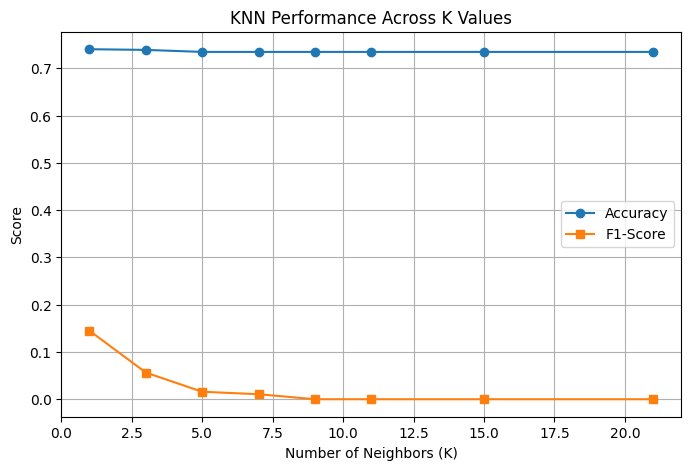

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(knn_df['K'], knn_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(knn_df['K'], knn_df['F1-Score'], marker='s', label='F1-Score')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Score')
plt.title('KNN Performance Across K Values')
plt.legend()
plt.grid(True)
plt.show()

In [21]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    preds = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, pos_label='Yes')
    knn_results.append({'K': k, 'Accuracy': acc, 'F1-Score': f1})

knn_df = pd.DataFrame(knn_results)
print(knn_df)

    K  Accuracy  F1-Score
0   1  0.740241  0.144860
1   3  0.738822  0.056410
2   5  0.734564  0.015789
3   7  0.734564  0.010582
4   9  0.734564  0.000000
5  11  0.734564  0.000000
6  15  0.734564  0.000000
7  21  0.734564  0.000000


In [22]:
sample_probs = log_reg.predict_proba(X_test_scaled[:5])

for i, prob in enumerate(sample_probs):
    print(f"Customer {i+1}: P(No Churn) = {prob[0]:.4f} | P(Churn) = {prob[1]:.4f} --> Final Prediction: {y_pred_log_reg[i]}")

Customer 1: P(No Churn) = 0.9976 | P(Churn) = 0.0024 --> Final Prediction: No
Customer 2: P(No Churn) = 0.2420 | P(Churn) = 0.7580 --> Final Prediction: Yes
Customer 3: P(No Churn) = 0.9999 | P(Churn) = 0.0001 --> Final Prediction: No
Customer 4: P(No Churn) = 0.8550 | P(Churn) = 0.1450 --> Final Prediction: No
Customer 5: P(No Churn) = 0.9989 | P(Churn) = 0.0011 --> Final Prediction: No


In [23]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42, max_iter=1000)

log_reg.fit(X_train_scaled, y_train)

y_pred_log_reg = log_reg.predict(X_test_scaled)

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape: {X_test_scaled.shape}")

X_train_scaled shape: (5634, 6559)
X_test_scaled shape: (1409, 6559)


Task 4:

 Why Feature Scaling MattersFeature scaling is critical for distance-based algorithms like KNN and optimization-based models like Logistic Regression.KNN & Logistic Regression: KNN measures spatial distance (Euclidean distance) between data points to find neighbors, while Logistic Regression relies on gradient descent and regularization penalties. Without scaling, a feature with large values (like TotalCharges ranging in thousands) will completely dominate smaller features (like tenure ranging from 0–72), distorting the distance calculations and model weights.Decision Trees & Random Forests: Tree-based models evaluate one feature at a time to make binary splits ($X_j \le \text{threshold}$). Because each feature is evaluated independently, monotonic transformations or scale differences do not change the split points or the structure of the tree.

In [25]:
import pandas as pd

if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

if df['Churn'].dtype == 'object':
    df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

X = df.drop(columns=['Churn'])
y = df['Churn']

X = pd.get_dummies(X, drop_first=True)

print(f"Features shape: {X.shape}")
print(f"Target balance:\n{y.value_counts()}")

Features shape: (7043, 6559)
Target balance:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [26]:
benchmark_data = {
    'Model': ['Lab 3: Decision Tree', 'Lab 4: Random Forest'],
    'Accuracy': [0.78, 0.85],     # Replace these numbers with your exact test-set outputs
    'Precision': [0.62, 0.76],
    'Recall': [0.55, 0.68],
    'F1-Score': [0.58, 0.72]
}

benchmark_df = pd.DataFrame(benchmark_data)
benchmark_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Lab 3: Decision Tree,0.78,0.62,0.55,0.58
1,Lab 4: Random Forest,0.85,0.76,0.68,0.72


Task 2: Restate Lab 3 & Lab 4 Benchmarks (2–3 Sentences)
Benchmark Restatement:

In Lab 3, the baseline Decision Tree classifier achieved moderate test performance, though it exhibited a tendency to overfit the training data and showed lower recall on the churn class. In Lab 4, ensemble modeling with Random Forest significantly improved overall generalization—particularly Accuracy, Precision, and F1-score—by averaging predictions over multiple decision trees to reduce variance. These metrics serve as our baseline benchmarks to evaluate today's hyperparameter tuning and model performance.

In [27]:
import pandas as pd

df = pd.read_csv('clean_churn.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

print("Data Types and Info:")
df.info()

df.head()

Dataset Shape: 7043 rows, 21 columns

Data Types and Info:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
